In [1]:
import tskit 
import pandas as pd
import numpy as np
from lets_plot import *
LetsPlot.setup_html()
import pickle
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

chromosome = 15

In [2]:
ts = tskit.load("/sietch_colab/jobste/Singer_scl/Chr" + str(chromosome) + "/Chr" + str(chromosome) + "_NonHybrid_99.trees")

In [3]:
meta = pd.read_csv("/sietch_colab/jobste/Data/TsinferMetaData_Vcf.txt")
meta.head()
allMeta = pd.read_csv("/sietch_colab/jobste/Data/DataDescriptor_SampleMeta.csv")
allMeta.head()
meta.loc[:, "Country"] = [allMeta.Country[allMeta.Run == x].to_list()[0] for x in meta.ID]

samples = pd.read_csv("/sietch_colab/jobste/Data/Remapped/NonHybrid_samples.txt", header = None, names = ["ID"])

# %%
# Add subpop as pop

sampleMeta = samples.merge(meta, how = "left", on = "ID")


complex_schema_pop = tskit.MetadataSchema({
    'codec': 'json',
    'additionalProperties': False,
    'properties': {'pop': {'description': 'Lineage',
                           'type': 'string'},
                   'subpop': {'description': 'Subspecies',
                           'type': 'string'}},
    'required': ['pop'],
    'type': 'object',
})

tables = ts.dump_tables()
tables.populations.metadata_schema = complex_schema_pop

# Add data to population table
popdata_column = [{"pop": pop, "subpop":subpop} for pop,subpop in set(list(zip(sampleMeta.Pop, sampleMeta.SubPop)))]
encoded_popdata_column = [
    tables.populations.metadata_schema.validate_and_encode_row(r) for r in popdata_column
]
md, md_offset = tskit.pack_bytes(encoded_popdata_column)
tables.populations.set_columns(metadata=md, metadata_offset=md_offset)


# %%
popDict = {y: x for x,y in enumerate(set(list(zip(sampleMeta.Pop, sampleMeta.SubPop))))}
ind_nodes = list([x.id for x in ts.nodes() if x.time == 0.0])
ind_pops = [popDict[(sampleMeta.Pop.to_list()[x], sampleMeta.SubPop.to_list()[x])] for x in ind_nodes]


# %%
indNodePop = tables.nodes.population
indNodePop[ind_nodes] = ind_pops
tables.nodes.population = indNodePop
ts_meta = tables.tree_sequence()

In [228]:
sibsMeta = pd.read_csv("/sietch_colab/jobste/Data/AmelHap-Metadata.csv")
sibsMeta.Reported_Sibling = sibsMeta.Reported_Sibling.astype(str)

nonNone = [x != "nan" for x in sibsMeta.Reported_Sibling]
sibsMeta[nonNone].Reported_Type.value_counts()

Reported_Type
Admixed       288
Mellifera      77
Scutellata     29
Capensis       28
Name: count, dtype: int64

In [229]:
from collections import Counter
from random import sample

familySampling = sibsMeta[nonNone]
print(len(set(familySampling.Reported_Sibling)))
kept = []
for family in set(familySampling.Reported_Sibling):
    kept.append(sample(familySampling.ENA_Run[familySampling.Reported_Sibling == family].to_list(), 1)[0])
removed = set(familySampling.ENA_Run) - set(kept)
pd.DataFrame({"ID": list(removed)}).to_csv("RemovedSibling.txt", index = None, header=None)

119


In [230]:
ind_nodes_by_ind = [[x] for x in ind_nodes]

In [266]:
indPairs = []
for ind1 in ind_nodes:
    for ind2 in ind_nodes[(ind1):]:
        indPairs.append((ind1, ind2))

In [279]:
indPairs = []
for ind1 in ind_nodes:
    for ind2 in ind_nodes[(ind1):]:
        indPairs.append((ind1, ind2))
        
indPairsDivergence = ts_meta.divergence(sample_sets = ind_nodes_by_ind, indexes = indPairs)
indPairsGRM = ts_meta.genetic_relatedness(sample_sets = ind_nodes_by_ind, indexes = indPairs)




In [280]:
indPairsDivergenceDF = pd.DataFrame({"Divergence": indPairsDivergence, "Pair": indPairs})
indPairsGRMDF = pd.DataFrame({"IBS": indPairsGRM, "Pair": indPairs})

In [281]:
indPairsDivergenceDF

,Divergence,Pair
0,NaN,"(0, 0)"
1,0.002141,"(0, 1)"
2,0.002424,"(0, 2)"
3,0.001724,"(0, 3)"
4,0.002491,"(0, 4)"
...,...,...
173161,0.004570,"(585, 586)"
173162,0.001583,"(585, 587)"
173163,NaN,"(586, 586)"
173164,0.004667,"(586, 587)"


In [282]:

indPairsDivergenceDF.loc[:, "Ind1"] = [x[0] for x in indPairsDivergenceDF.Pair]
indPairsDivergenceDF.loc[:, "Ind2"] = [x[1] for x in indPairsDivergenceDF.Pair]
indPairsDivergenceDF.loc[:, "IndName1"] = [sampleMeta.ID[x] for x in indPairsDivergenceDF.Ind1]
indPairsDivergenceDF.loc[:, "IndName2"] = [sampleMeta.ID[x] for x in indPairsDivergenceDF.Ind2]
indPairsDivergenceDF.loc[:, "Subpop1"] = [ts_meta.population(ts_meta.node(x).population).metadata["subpop"] for x in indPairsDivergenceDF.Ind1]
indPairsDivergenceDF.loc[:, "Subpop2"] = [ts_meta.population(ts_meta.node(x).population).metadata["subpop"] for x in indPairsDivergenceDF.Ind2]
indPairsGRMDF.loc[:, "Ind1"] = [x[0] for x in indPairsGRMDF.Pair]
indPairsGRMDF.loc[:, "Ind2"] = [x[1] for x in indPairsGRMDF.Pair]
indPairsGRMDF.loc[:, "IndName1"] = [sampleMeta.ID[x] for x in indPairsGRMDF.Ind1]
indPairsGRMDF.loc[:, "IndName2"] = [sampleMeta.ID[x] for x in indPairsGRMDF.Ind2]
indPairsGRMDF.loc[:, "Subpop1"] = [ts_meta.population(ts_meta.node(x).population).metadata["subpop"] for x in indPairsGRMDF.Ind1]
indPairsGRMDF.loc[:, "Subpop2"] = [ts_meta.population(ts_meta.node(x).population).metadata["subpop"] for x in indPairsGRMDF.Ind2]


In [284]:
indPairsDivergenceDF.loc[:, "Family1"] = [sibsMeta.Reported_Sibling[sibsMeta.ENA_Run == x] for x in indPairsDivergenceDF.IndName1]
indPairsDivergenceDF.loc[:, "Family2"] = [sibsMeta.Reported_Sibling[sibsMeta.ENA_Run == x] for x in indPairsDivergenceDF.IndName2]

#indPairsDivergenceDF.to_csv("IndPairsDivergence_Chr" + str(chromosome) + ".csv", index = None)
#indPairsGRMDF.to_csv("IndPairsGRM_Chr" + str(chromosome) + ".csv", index = None)

In [285]:
indPairsGRMDF.loc[:, "Family1"] = [sibsMeta.Reported_Sibling[sibsMeta.ENA_Run == x].to_list()[0] for x in indPairsGRMDF.IndName1.to_list()]
indPairsGRMDF.loc[:, "Family2"] = [sibsMeta.Reported_Sibling[sibsMeta.ENA_Run == x].to_list()[0] for x in indPairsGRMDF.IndName2.to_list()]


In [286]:
indPairsGRMDF.loc[:, "Country1"] = [sibsMeta.Sample_Country[sibsMeta.ENA_Run == x].to_list()[0] for x in indPairsGRMDF.IndName1.to_list()]
indPairsGRMDF.loc[:, "Country2"] = [sibsMeta.Sample_Country[sibsMeta.ENA_Run == x].to_list()[0] for x in indPairsGRMDF.IndName2.to_list()]


In [287]:
indPairsGRMDF.loc[:, "Locale1"] = [sibsMeta.Sample_Locale[sibsMeta.ENA_Run == x].to_list()[0] for x in indPairsGRMDF.IndName1.to_list()]
indPairsGRMDF.loc[:, "Locale2"] = [sibsMeta.Sample_Locale[sibsMeta.ENA_Run == x].to_list()[0] for x in indPairsGRMDF.IndName2.to_list()]


In [288]:
indPairsDivergenceDF.loc[:, "PopPair"] = ["Same" if indPairsDivergenceDF.Subpop1[x] == indPairsDivergenceDF.Subpop2[x] else "Different" for x in range(len(indPairsDivergenceDF))]
indPairsDivergenceDF.loc[:, "FamilyPair"] = ["Same" if indPairsDivergenceDF.Family1[x] == indPairsDivergenceDF.Family2[x] else "Different" for x in range(len(indPairsDivergenceDF))]


In [289]:
indPairsGRMDF.loc[:, "PopPair"] = ["Same" if indPairsGRMDF.Subpop1[x] == indPairsGRMDF.Subpop2[x] else "Different" for x in range(len(indPairsGRMDF))]
indPairsGRMDF.loc[:, "FamilyPair"] = ["Same" if indPairsGRMDF.Family1[x] == indPairsGRMDF.Family2[x] else "Different" for x in range(len(indPairsGRMDF))]

In [290]:
indPairsDivergenceDF.to_csv("IndPairsDivergence_Chr" + str(chromosome) + ".csv", index = None)
indPairsGRMDF.to_csv("IndPairsGRM_Chr" + str(chromosome) + ".csv", index = None)

In [6]:
from pandas.api.types import CategoricalDtype
indPairsDivergenceDF = pd.read_csv("IndPairsDivergence_Chr15.csv")
indPairsGRMDF = pd.read_csv("IndPairsGRM_Chr15.csv")

indPairsDivergenceDF.loc[:, "PopPair"] = ["Same" if indPairsDivergenceDF.Subpop1[x] == indPairsDivergenceDF.Subpop2[x] else "Different" for x in range(len(indPairsDivergenceDF))]
indPairsGRMDF.loc[:, "PopPair"] = ["Same" if indPairsGRMDF.Subpop1[x] == indPairsGRMDF.Subpop2[x] else "Different" for x in range(len(indPairsGRMDF))]



#family_type = CategoricalDtype(categories=["Same", "Different"], ordered=True)
#indPairsDivergenceDF.FamilyPair = indPairsDivergenceDF.FamilyPair.astype(family_type)
#indPairsGRMDF.FamilyPair = indPairsGRMDF.FamilyPair.astype(family_type)

/tmp/ipykernel_557262/4109165374.py:3: DtypeWarning: Columns (8) have mixed types. Specify dtype option on import or set low_memory=False.
  indPairsGRMDF = pd.read_csv("IndPairsGRM_Chr15.csv")


In [4]:
#Remove the reported and identified  siblings
reportedSiblings = pd.read_csv("ReportedSibling.txt", header = None, names = ["ID"])
identifiedSiblings = pd.read_csv("IdentifiedSiblings.txt")
identifiedMissclass = pd.read_csv("IdentifiedMissclass.txt")

remove = pd.concat([reportedSiblings, identifiedSiblings, identifiedMissclass])

In [7]:
indPairsDivergenceDF = indPairsDivergenceDF[~((indPairsDivergenceDF.IndName1.isin(remove.ID)) | (indPairsDivergenceDF.IndName2.isin(remove.ID)))].reset_index()

/tmp/ipykernel_557262/469025038.py:10: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


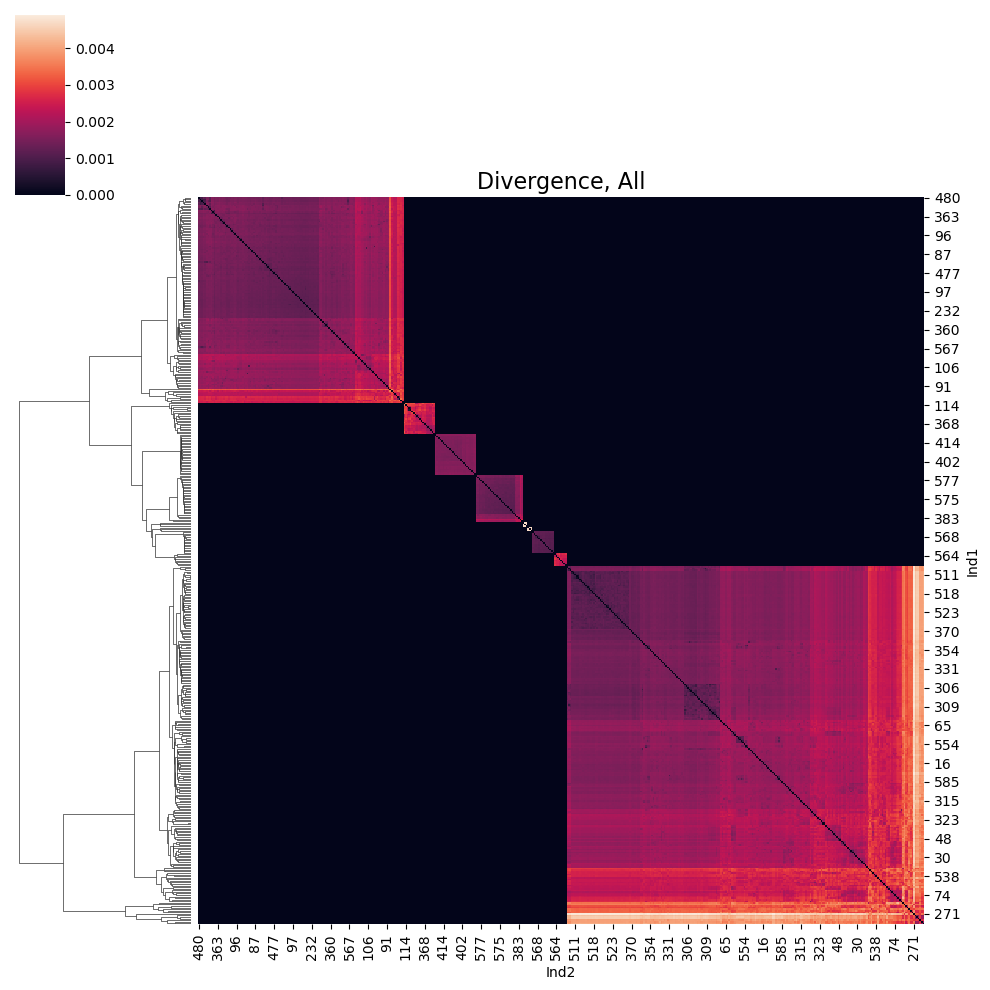

In [8]:
name = "All"
m = indPairsDivergenceDF[(indPairsDivergenceDF.PopPair == "Same")][["Ind1", "Ind2", "Divergence"]]
numberNames = indPairsDivergenceDF[["Ind1", "IndName1"]].drop_duplicates()
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
orderNames = [numberNames.IndName1.to_list()[x] for x in list(order)]
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

/tmp/ipykernel_557262/3016735039.py:12: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


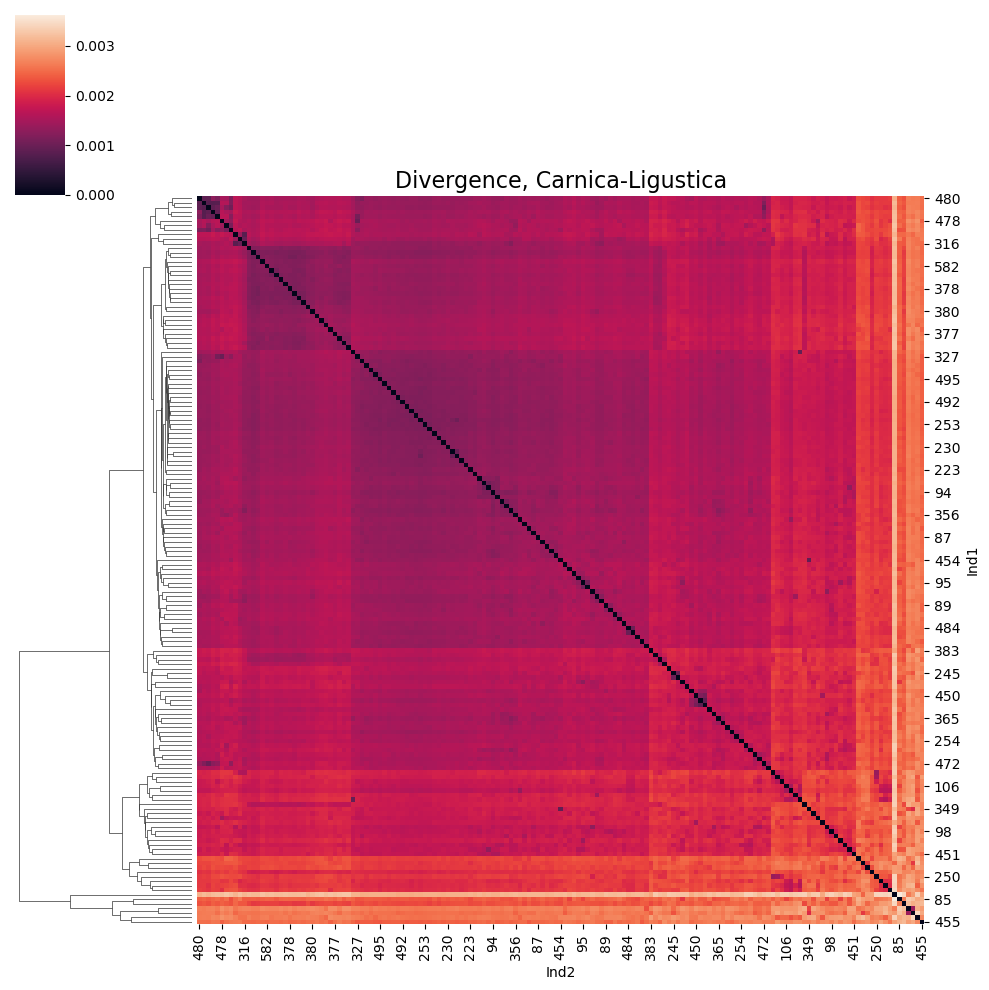

In [9]:
#Lineages 
#C
names = ["Carnica", "Ligustica"]

m = indPairsDivergenceDF[(indPairsDivergenceDF.Subpop1.isin(names)) & (indPairsDivergenceDF.Subpop2.isin(names))][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Get the names in order
numberNames = indPairsDivergenceDF[["Ind1", "IndName1"]].drop_duplicates()
orderNames = [numberNames.IndName1.to_list()[x] for x in list(order)]

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + "-".join(names), fontsize=16)

plt.show()

In [126]:
#Two cluster
max_d = 0.01 # example distance threshold
clusters = scipy.cluster.hierarchy.fcluster(row_linkage, max_d, criterion='distance')
print(len(set(clusters)))
from collections import Counter
Counter(clusters)

2


Counter({1: 154, 2: 7})

In [127]:
keep = [ind for ind,cluster in zip(matrixAll.index.values, clusters) if cluster == 1]
keepNames = [numberNames.IndName1[numberNames.Ind1 == x].to_list()[0] for x in keep]
len(keepNames)

154

/tmp/ipykernel_1151356/3266446096.py:2: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAllKept, method="average")


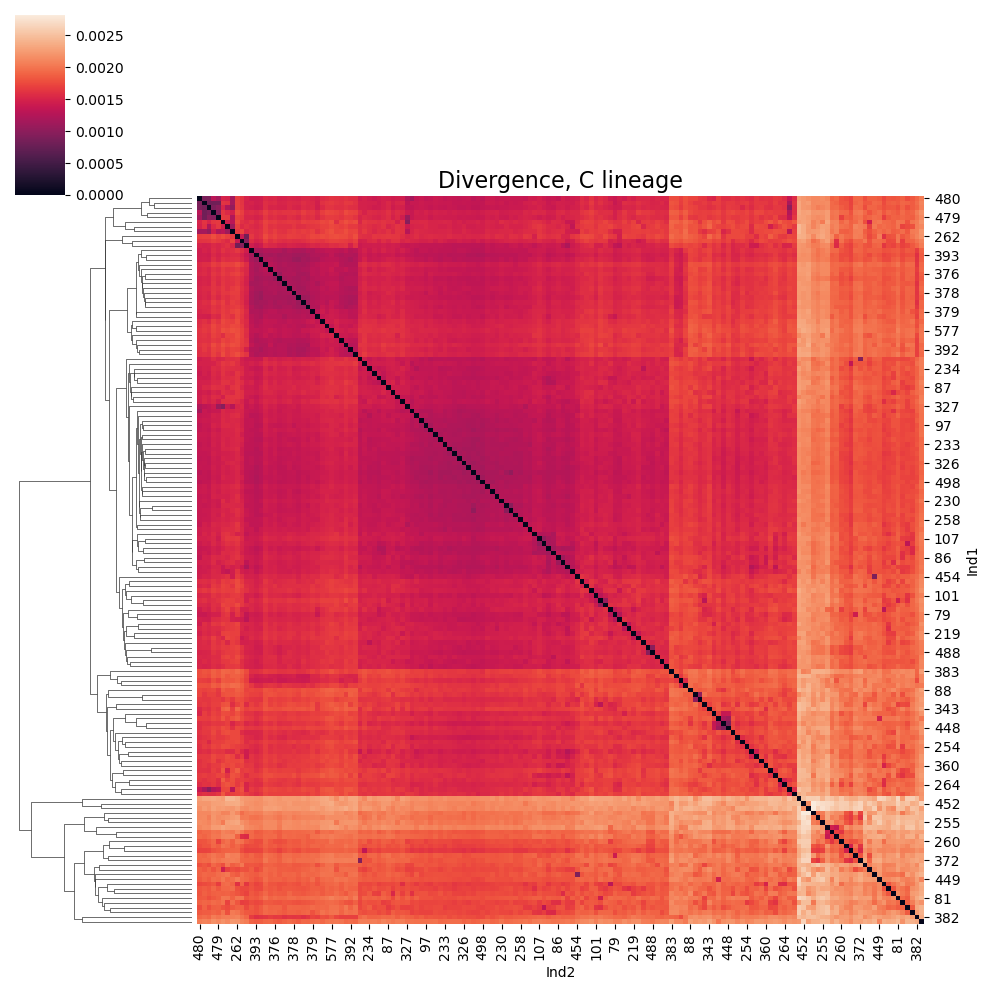

In [160]:
matrixAllKept = matrixAll.loc[keep, keep]
row_linkage = scipy.cluster.hierarchy.linkage(matrixAllKept, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAllKept.index.values[order]]
clustermap = sns.clustermap(matrixAllKept[x_pop], row_linkage=row_linkage, col_cluster=False)

# Get the names in order
orderNames = [keepNames[x] for x in list(order)]


# Add title
clustermap.ax_heatmap.set_title("Divergence, C lineage", fontsize=16)

plt.show()

/tmp/ipykernel_1151356/3305328233.py:11: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


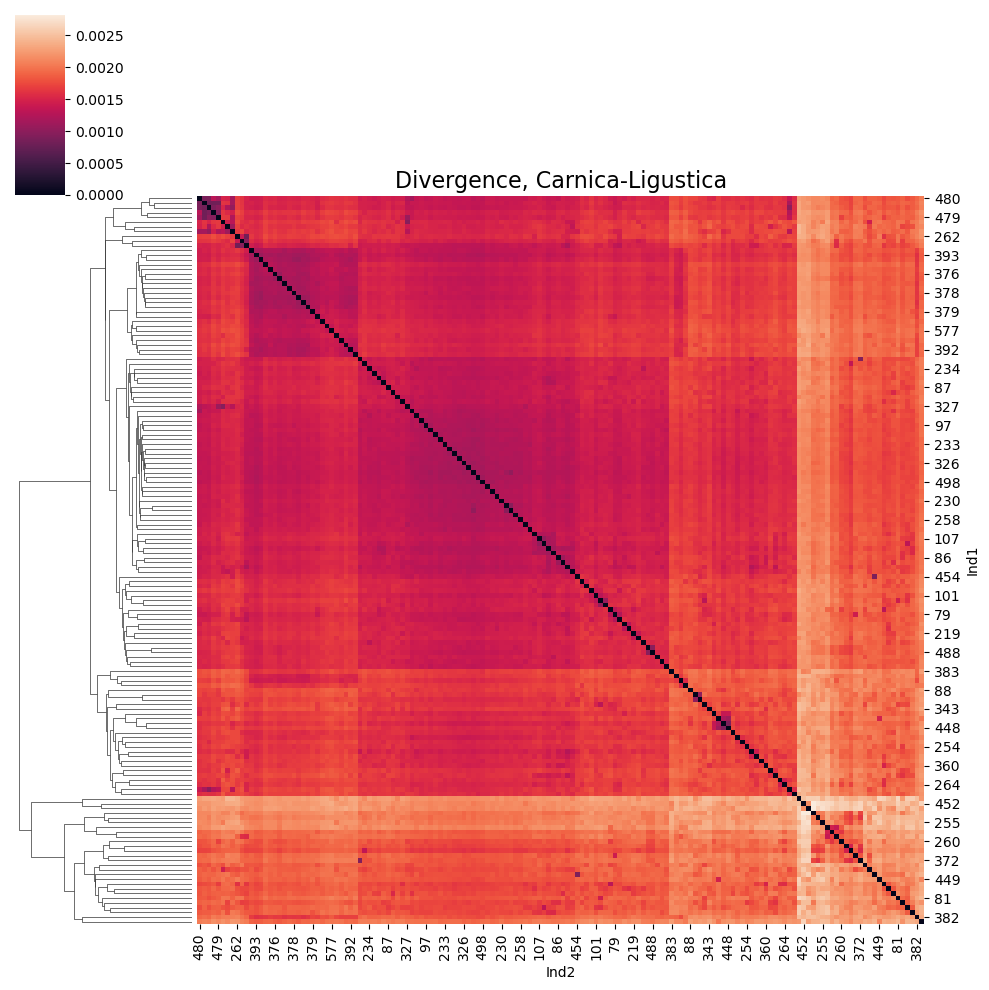

In [162]:
# Just to make sure I'm doing the right thing with the names - I am
names = ["Carnica", "Ligustica"]

m = indPairsDivergenceDF[(indPairsDivergenceDF.IndName1.isin(keepNames)) & (indPairsDivergenceDF.IndName2.isin(keepNames))][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Get the names in order
numberNames = indPairsDivergenceDF[["Ind1", "IndName1"]].drop_duplicates()
orderNames = [numberNames.IndName1.to_list()[x] for x in list(order)]

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + "-".join(names), fontsize=16)

plt.show()

In [158]:
Counter([x in keepNames for x in orderNames])

Counter({False: 106, True: 48})

/tmp/ipykernel_777621/1774977592.py:12: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


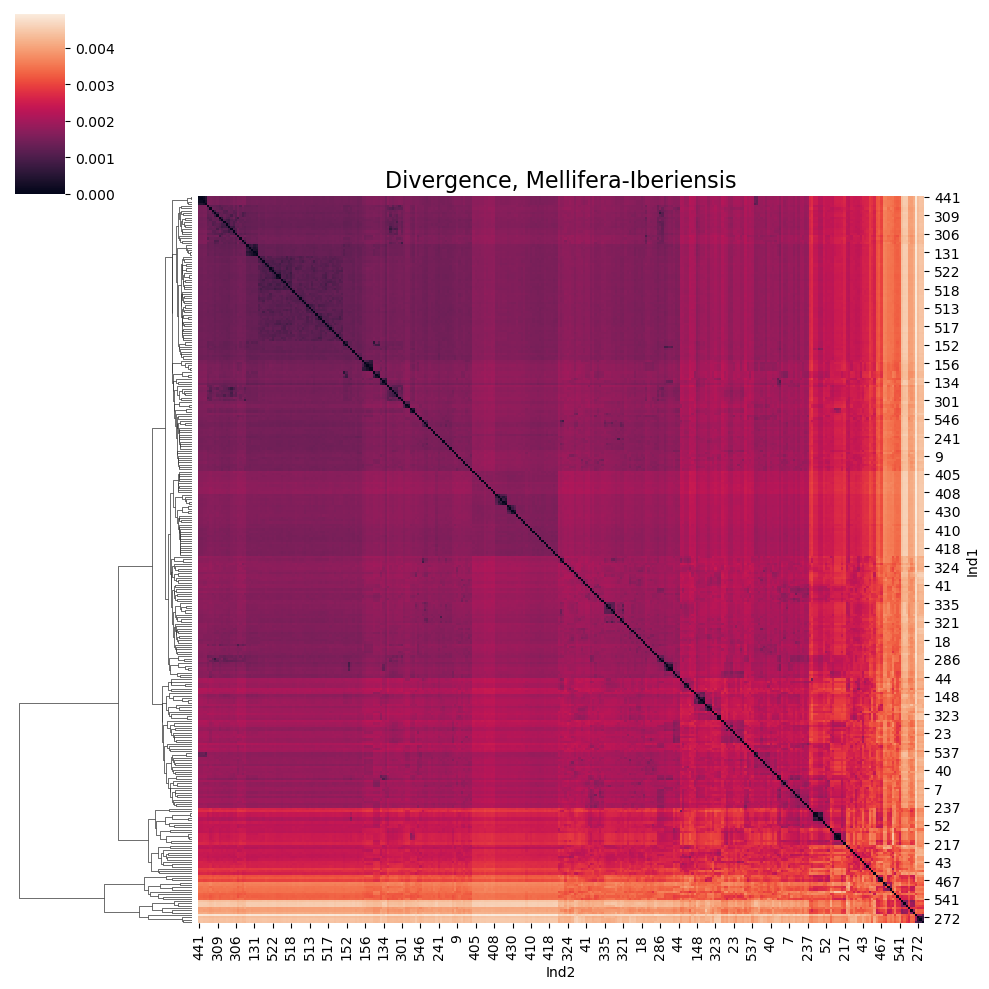

In [120]:
#Lineages 
#M
names = ["Mellifera", "Iberiensis"]

m = indPairsDivergenceDF[(indPairsDivergenceDF.Subpop1.isin(names)) & (indPairsDivergenceDF.Subpop2.isin(names))][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1


In [128]:
#Two cluster
max_d = 0.01 # example distance threshold
clusters = scipy.cluster.hierarchy.fcluster(row_linkage, max_d, criterion='distance')
print(len(set(clusters)))
from collections import Counter
Counter(clusters)

4


Counter({1: 265, 2: 29, 3: 11, 4: 10})

In [104]:
keep = [ind for ind,cluster in zip(matrixAll.index.values, clusters) if cluster == 1]
keepNames = [numberNames.IndName1[numberNames.Ind1 == x].to_list()[0] for x in keep]
len(keepNames)


147

/tmp/ipykernel_777621/2328086188.py:12: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


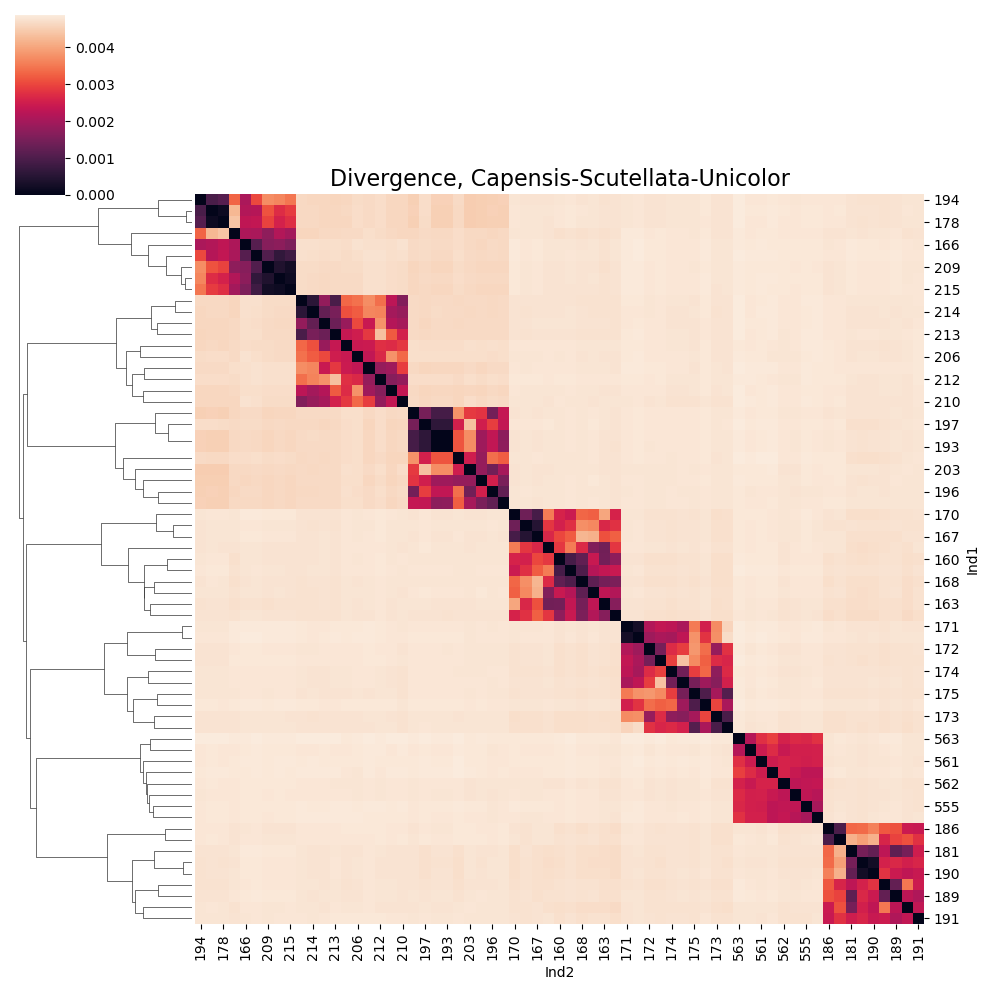

In [131]:
#Lineages 
#A
names = ["Capensis", "Scutellata", "Unicolor"]

m = indPairsDivergenceDF[(indPairsDivergenceDF.Subpop1.isin(names)) & (indPairsDivergenceDF.Subpop2.isin(names))][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Get the names in order
numberNames = indPairsDivergenceDF[["Ind1", "IndName1"]].drop_duplicates()
orderNames = [numberNames.IndName1[numberNames.Ind1 == x].to_list()[0] for x in list(order)]

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + "-".join(names), fontsize=16)

plt.show()

In [132]:
set(indPairsDivergenceDF.Subpop1)

{'Buckfast',
 'Capensis',
 'Carnica',
 'Caucasia',
 'Iberiensis',
 'Ligustica',
 'Mellifera',
 'Scutellata',
 'Unicolor'}

/tmp/ipykernel_777621/2784905372.py:12: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


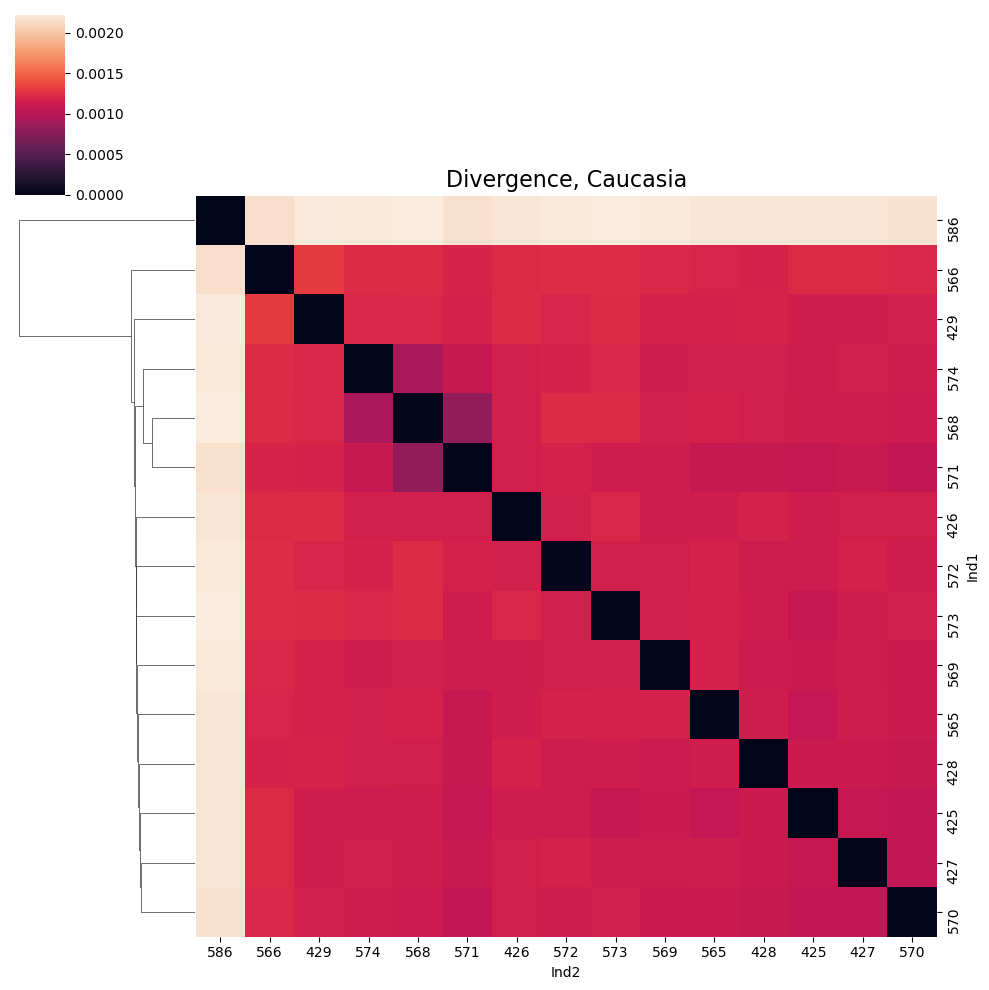

In [133]:
#Lineages 
#O
names = ["Caucasia"]

m = indPairsDivergenceDF[(indPairsDivergenceDF.Subpop1.isin(names)) & (indPairsDivergenceDF.Subpop2.isin(names))][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Get the names in order
numberNames = indPairsDivergenceDF[["Ind1", "IndName1"]].drop_duplicates()
orderNames = [numberNames.IndName1[numberNames.Ind1 == x].to_list()[0] for x in list(order)]

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + "-".join(names), fontsize=16)

plt.show()

matrix.head()

/tmp/ipykernel_777621/3723413814.py:9: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


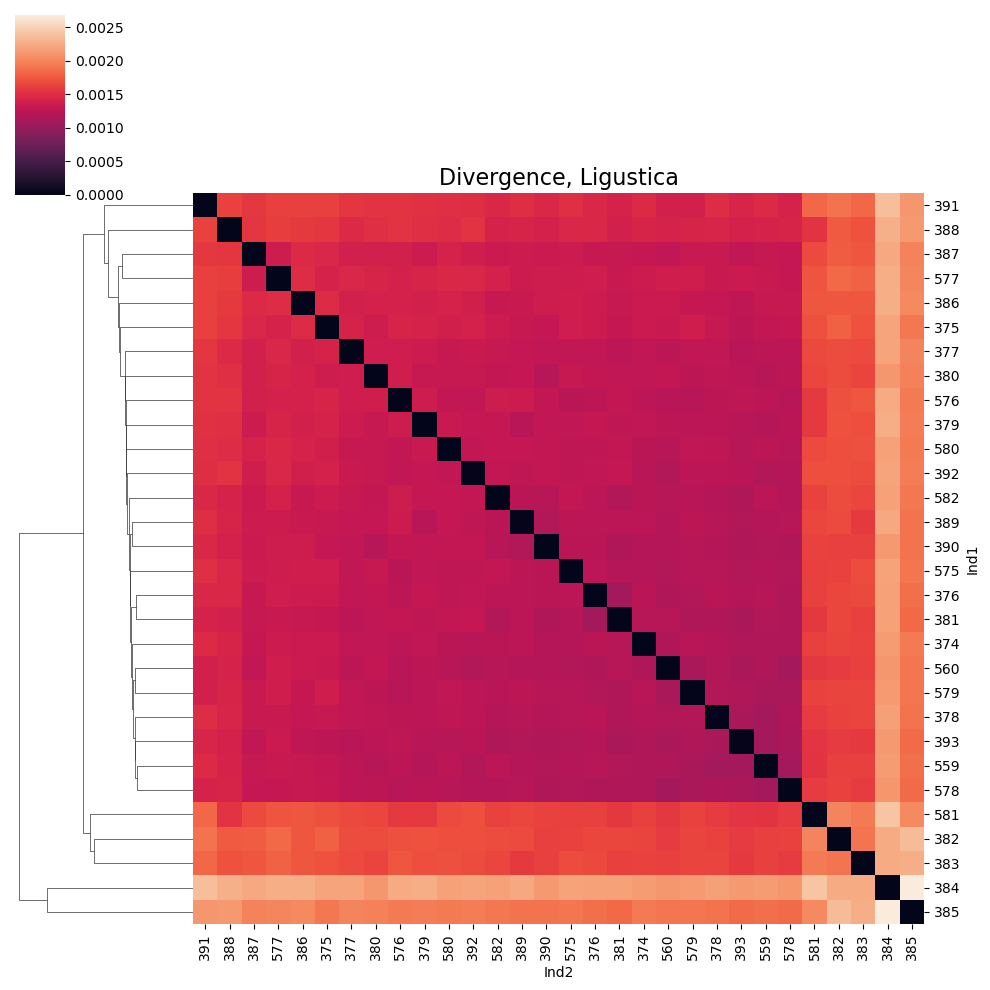

In [25]:
name = "Ligustica"
m = indPairsDivergenceDF[(indPairsDivergenceDF.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Get the names in order
numberNames = indPairsDivergenceDF[["Ind1", "IndName1"]].drop_duplicates()
orderNames = [numberNames.IndName1[numberNames.Ind1 == x].to_list()[0] for x in list(order)]

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()


In [76]:
max_d = 0.003 # example distance threshold
clusters = scipy.cluster.hierarchy.fcluster(row_linkage, max_d, criterion='distance')

/tmp/ipykernel_723849/493199476.py:9: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


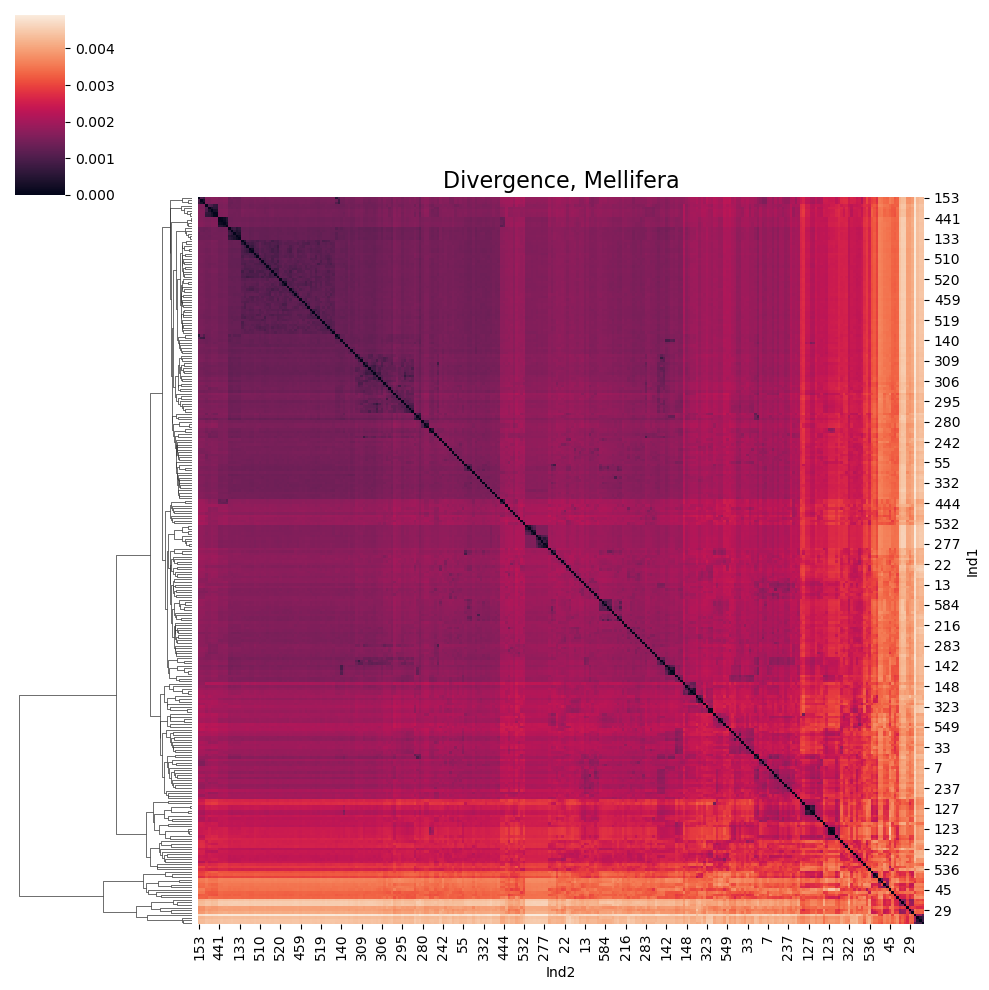

In [26]:
name = "Mellifera"
m = indPairsDivergenceDF[(indPairsDivergenceDF.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()


In [27]:
indPairsGRMDF = indPairsGRMDF[list(indPairsGRMDF.Ind1 != indPairsGRMDF.Ind2)]
indPairsDivergenceDF = indPairsDivergenceDF[list(indPairsDivergenceDF.Ind1 != indPairsDivergenceDF.Ind2)]

In [28]:
print(indPairsGRMDF.Subpop1[indPairsGRMDF.FamilyPair == "Same"].value_counts())
print(indPairsDivergenceDF.Subpop1[indPairsDivergenceDF.FamilyPair == "Same"].value_counts())


Subpop1
Mellifera     159
Scutellata    126
Capensis      117
Name: count, dtype: int64
Subpop1
Mellifera     159
Scutellata    126
Capensis      117
Name: count, dtype: int64


In [29]:
name = "Mellifera"
ggplot(data = indPairsDivergenceDF[(indPairsDivergenceDF.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)]) + geom_density(aes(x = "Divergence", colour = "FamilyPair"), position = "dodge")

In [30]:
name = "Mellifera"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_density(aes(x = "IBS", colour = "FamilyPair"), position = "dodge")

In [31]:
name="Mellifera"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_density(aes(x = "IBS"), position = "dodge")

In [32]:
name = "Iberiensis"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_histogram(aes(x = "IBS", colour = "FamilyPair", fill = "FamilyPair"), position = "dodge")

In [33]:
name = "Iberiensis"
potentialMisclass = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name) & (indPairsGRMDF.IBS < 0.015)]

In [34]:
#369 potentially misclassified - SRR15173748
iberiensisMisclass = ["SRR15173748"]

ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name) &  ~((indPairsGRMDF.IndName1 == "SRR15173748") | (indPairsGRMDF.IndName2 == "SRR15173748"))]) + \
    geom_histogram(aes(x = "IBS", colour = "FamilyPair", fill = "FamilyPair"), position = "dodge")

In [35]:
name = "Iberiensis"
iberiensisSiblings = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name) & (indPairsGRMDF.IBS > 0.02)]
# POtential two pairs
{x: [iberiensisSiblings.IndName1.to_list()[x], iberiensisSiblings.IndName2.to_list()[x]] for x in range(len(iberiensisSiblings))}

{0: ['SRR15173756', 'SRR15173762'], 1: ['SRR15173770', 'SRR15173771']}

In [36]:
iberiensisSiblings

,IBS,Pair,Ind1,Ind2,IndName1,IndName2,Subpop1,Subpop2,Family1,Family2,PopPair,FamilyPair,Country1,Country2,Locale1,Locale2
155967,0.020027,"(403, 409)",403,409,SRR15173756,SRR15173762,Iberiensis,Iberiensis,NaN,NaN,Same,Different,Spain,Spain,Central Transect 9,Central Transect 9
158289,0.022426,"(416, 417)",416,417,SRR15173770,SRR15173771,Iberiensis,Iberiensis,NaN,NaN,Same,Different,Spain,Spain,Central Transect 1,Central Transect 1


In [37]:
name = "Carnica"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_density(aes(x = "IBS", colour = "FamilyPair"), position = "dodge")

In [38]:
name = "Carnica"
indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name) & (indPairsGRMDF.IBS < 0)]

,IBS,Pair,Ind1,Ind2,IndName1,IndName2,Subpop1,Subpop2,Family1,Family2,PopPair,FamilyPair,Country1,Country2,Locale1,Locale2
267,-0.014906,"(0, 267)",0,267,ERR1700768,SRR10714418,Carnica,Carnica,NaN,NaN,Same,Different,Switzerland,Germany,Ticino,Bayrisch Gmain
854,-0.010286,"(1, 267)",1,267,ERR1700769,SRR10714418,Carnica,Carnica,NaN,NaN,Same,Different,Switzerland,Germany,Ticino,Bayrisch Gmain
42029,-0.013103,"(76, 267)",76,267,ERR1700845,SRR10714418,Carnica,Carnica,NaN,NaN,Same,Different,Switzerland,Germany,NaN,Bayrisch Gmain
42540,-0.011338,"(77, 267)",77,267,ERR1700846,SRR10714418,Carnica,Carnica,NaN,NaN,Same,Different,Switzerland,Germany,NaN,Bayrisch Gmain
43050,-0.011520,"(78, 267)",78,267,ERR1700847,SRR10714418,Carnica,Carnica,NaN,NaN,Same,Different,Switzerland,Germany,NaN,Bayrisch Gmain
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121713,-0.017961,"(267, 495)",267,495,SRR10714418,SRR3157171,Carnica,Carnica,NaN,NaN,Same,Different,Germany,Slovenia,Bayrisch Gmain,NaN
121714,-0.018112,"(267, 496)",267,496,SRR10714418,SRR3157172,Carnica,Carnica,NaN,NaN,Same,Different,Germany,Slovenia,Bayrisch Gmain,NaN
121715,-0.018306,"(267, 497)",267,497,SRR10714418,SRR3157173,Carnica,Carnica,NaN,NaN,Same,Different,Germany,Slovenia,Bayrisch Gmain,NaN
121716,-0.018341,"(267, 498)",267,498,SRR10714418,SRR3157174,Carnica,Carnica,NaN,NaN,Same,Different,Germany,Slovenia,Bayrisch Gmain,NaN


In [39]:
#There seems to be a group of bees from Byrisch Gmain that are different from the rest
carnicaMisclassLoc  = "Bayrisch Gmain"
carnicaMisclass = ["SRR10714418"]
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name) &  ~((indPairsGRMDF.IndName1 == carnicaMisclass[0]) | (indPairsGRMDF.IndName2 == carnicaMisclass[0]))]) + \
    geom_histogram(aes(x = "IBS", colour = "FamilyPair", fill = "FamilyPair"), position = "dodge")

In [40]:
name = "Carnica"
ggplot(data = indPairsDivergenceDF[(indPairsDivergenceDF.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)]) + geom_density(aes(x = "Divergence", colour = "FamilyPair"), position = "dodge")

In [41]:
name = "Carnica"
potentialSiblings = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name) & (indPairsGRMDF.IBS > 0.035)]

In [42]:
carnicaSiblings = []
for x,y in zip(potentialSiblings.IndName1.to_list(), potentialSiblings.IndName2.to_list()):
    if ((x in carnicaSiblings) | (x in carnicaSiblings)):
        continue
    else:
        carnicaSiblings.append(x)

In [43]:
carnicaSiblings

['SRR10714369',
 'SRR10714402',
 'SRR15173543',
 'SRR15173618',
 'SRR3157147',
 'SRR3157150',
 'SRR3157157',
 'SRR3157158',
 'SRR3157162',
 'SRR3157166',
 'SRR3157173']

In [44]:
name = "Ligustica"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_histogram(aes(x = "IBS", colour = "FamilyPair", fill = "FamilyPair"), position = "dodge")

In [45]:
name = "Caucasia"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_histogram(aes(x = "IBS", fill = "FamilyPair", colour = "FamilyPair"), position = "dodge")

In [46]:
name = "Caucasia"
potentialMisclass = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name) & (indPairsGRMDF.IBS < 0.04)]
potentialMisclass

,IBS,Pair,Ind1,Ind2,IndName1,IndName2,Subpop1,Subpop2,Family1,Family2,PopPair,FamilyPair,Country1,Country2,Locale1,Locale2
159961,0.033092,"(425, 586)",425,586,SRR15173873,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN
160123,0.033253,"(426, 586)",426,586,SRR15173874,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN
160284,0.033058,"(427, 586)",427,586,SRR15173875,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN
160444,0.033051,"(428, 586)",428,586,SRR15173876,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN
160603,0.032473,"(429, 586)",429,586,SRR15173877,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN
172911,0.033134,"(565, 586)",565,586,SRR6236933,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN
172933,0.033278,"(566, 586)",566,586,SRR6236934,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN
172974,0.032072,"(568, 586)",568,586,SRR6236938,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN
172993,0.032935,"(569, 586)",569,586,SRR6236939,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN
173011,0.033484,"(570, 586)",570,586,SRR6236940,SRR6236969,Caucasia,Caucasia,NaN,NaN,Same,Different,France,France,NaN,NaN


In [47]:
name = "Caucasia"
caucasiaMisclass = ["SRR6236969"]

ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name) &  ~((indPairsGRMDF.IndName1 == caucasiaMisclass[0]) | (indPairsGRMDF.IndName2 == caucasiaMisclass[0]))]) + \
    geom_histogram(aes(x = "IBS", colour = "FamilyPair", fill = "FamilyPair"), position = "dodge")

In [48]:
name = "Unicolor"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_histogram(aes(x = "IBS", colour = "FamilyPair", fill = "FamilyPair"), position = "dodge")

In [49]:
name = "Scutellata"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_histogram(aes(x = "IBS", colour = "FamilyPair", fill = "FamilyPair"), position = "dodge")

In [50]:
name = "Scutellata"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_density(aes(x = "IBS"), position = "dodge")

In [51]:
name = "Capensis"
ggplot(data = indPairsGRMDF[(indPairsGRMDF.PopPair == "Same") & (indPairsGRMDF.Subpop1 == name)]) + geom_histogram(aes(x = "IBS", colour = "FamilyPair", fill = "FamilyPair"), position = "dodge")

In [56]:
allSiblings = pd.DataFrame({"ID": iberiensisSiblings.IndName1.to_list() + carnicaSiblings})
allMisclass = pd.DataFrame({"ID": iberiensisMisclass + carnicaMisclass + caucasiaMisclass})

In [57]:
allSiblings

,ID
0,SRR15173756
1,SRR15173770
2,SRR10714369
3,SRR10714402
4,SRR15173543
5,SRR15173618
6,SRR3157147
7,SRR3157150
8,SRR3157157
9,SRR3157158


In [58]:
allSiblings.to_csv("IdentifiedSiblings.txt", index = None)
allMisclass.to_csv("IdentifiedMissclass.txt", index = None)

In [60]:
removeNames = pd.read_csv("/sietch_colab/jobste/Singer/RemovedSibling.txt", names = ["ID"])
removeSiblings = pd.read_csv("/sietch_colab/jobste/Singer/IdentifiedSiblings.txt")
removeMisclass = pd.read_csv("/sietch_colab/jobste/Singer/IdentifiedMissclass.txt")
remove = removeNames.ID.to_list() + removeSiblings.ID.to_list() + removeMisclass.ID.to_list()



In [61]:
indPairsDivergenceDF_removed = indPairsDivergenceDF[~((indPairsDivergenceDF.IndName1.isin(remove)) | (indPairsDivergenceDF.IndName2.isin(remove)))]

In [65]:
name = "All"
m = indPairsDivergenceDF_removed[(indPairsDivergenceDF_removed.PopPair == "Same")][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1


In [77]:
matrix


Ind2,1,3,4,6,7,8,9,10,11,12,...,577,578,579,580,581,582,583,584,585,587
Ind1,,,,,,,,,,,,,,,,,,,,,
0,0.002141,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
2,0.000000,0.002461,0.002977,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.002309,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
580,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.001674,0.001288,0.0,0.000000,0.000000,0.000000
581,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.001629,0.0,0.000000,0.000000,0.000000
583,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.001704,0.001788,0.001605


In [78]:
matrix1

Ind2,0,1,2,3,4,5,6,7,8,9,...,575,576,577,578,579,580,581,583,584,585
Ind1,,,,,,,,,,,,,,,,,,,,,
1,0.002141,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.0,0.002461,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.0,0.002977,0.002309,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
6,0.000000,0.0,0.000000,0.000000,0.0,0.002314,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,0.000000,0.0,0.000000,0.000000,0.0,0.002550,0.002324,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
582,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.001287,0.00136,0.001407,0.001183,0.001223,0.001288,0.001629,0.000000,0.000000,0.000000
583,0.000000,0.0,0.000000,0.000000,0.0,0.002454,0.002172,0.002077,0.001985,0.001756,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
584,0.000000,0.0,0.000000,0.000000,0.0,0.002577,0.002195,0.002170,0.001872,0.001794,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001704,0.000000,0.000000


In [66]:
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]

clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)
# Add title
clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

ValueError: The condensed distance matrix must contain only finite values.

/tmp/ipykernel_693684/2797190565.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  m = indPairsDivergenceDF_removed[(indPairsDivergenceDF_removed.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)][["Ind1", "Ind2", "Divergence"]]
/tmp/ipykernel_693684/2797190565.py:9: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


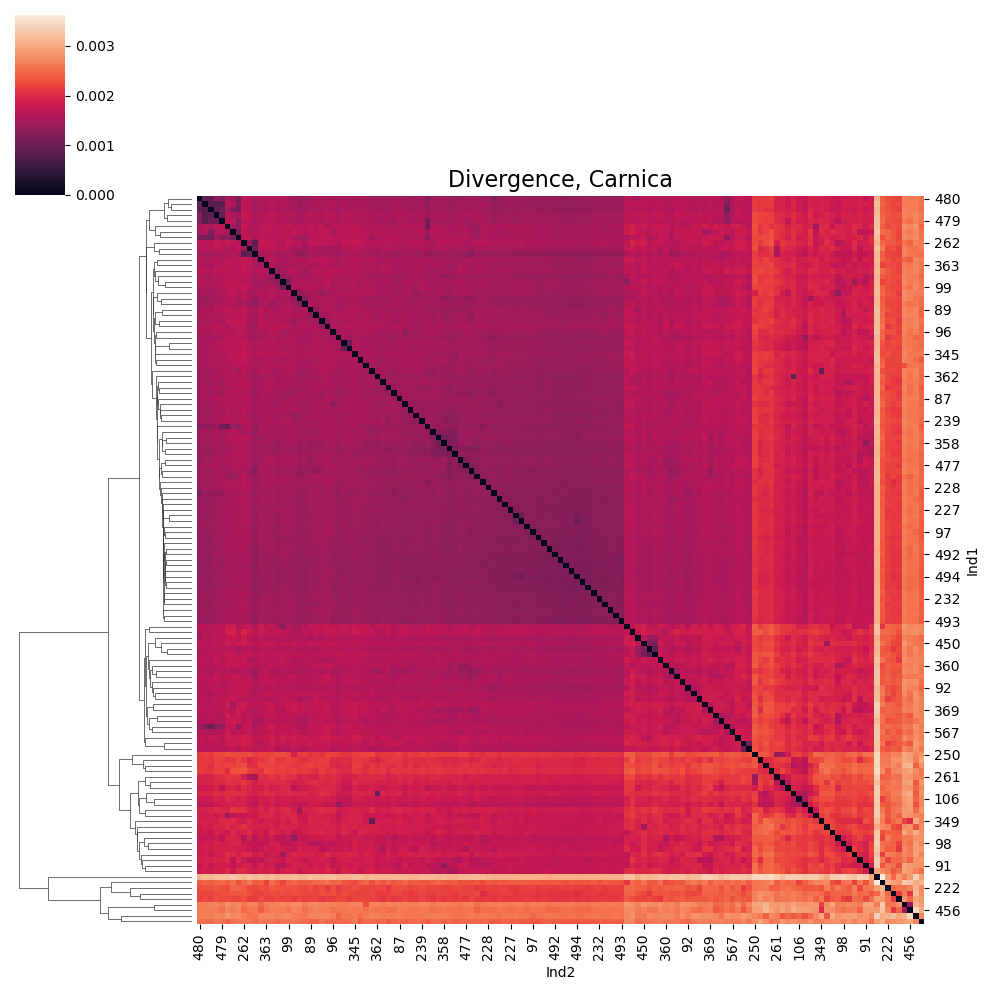

In [66]:
name = "Carnica"
m = indPairsDivergenceDF_removed[(indPairsDivergenceDF_removed.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

/tmp/ipykernel_693684/1827941523.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  m = indPairsDivergenceDF_removed[(indPairsDivergenceDF_removed.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)][["Ind1", "Ind2", "Divergence"]]
/tmp/ipykernel_693684/1827941523.py:9: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


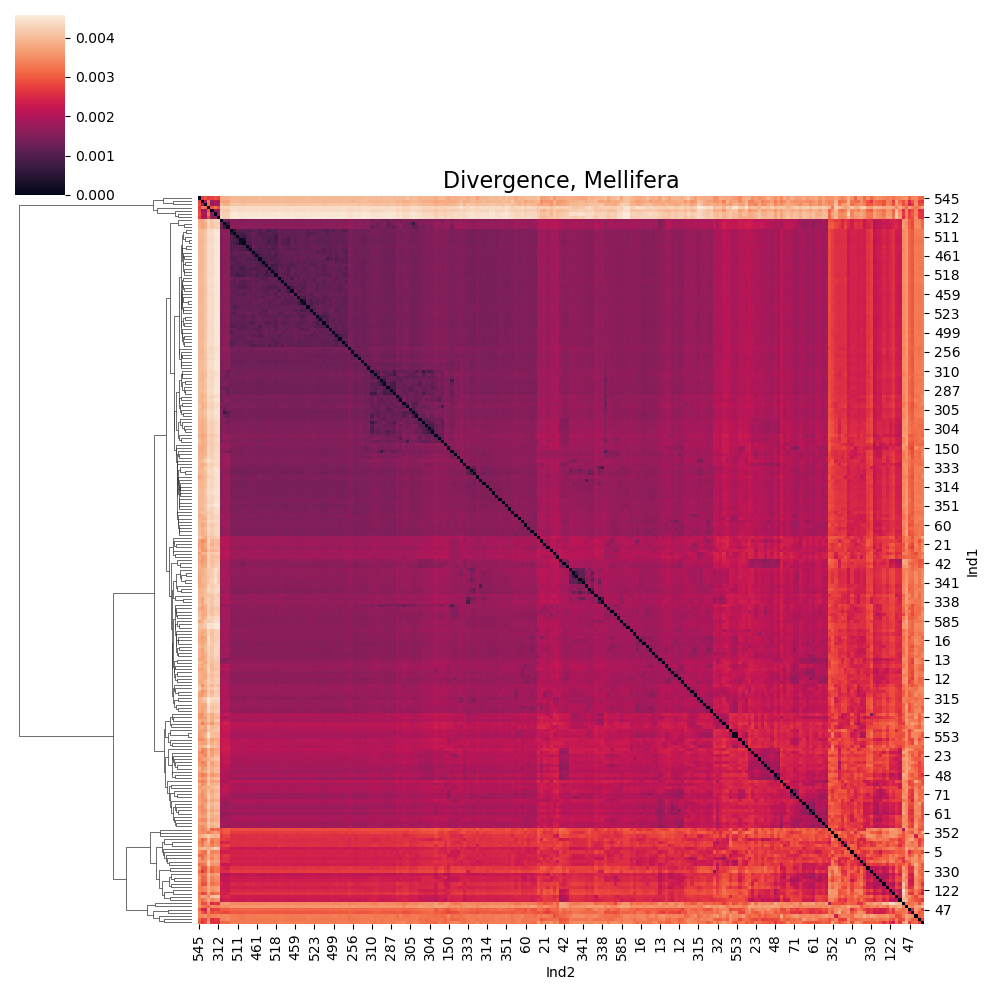

In [79]:
name = "Mellifera"
m = indPairsDivergenceDF_removed[(indPairsDivergenceDF_removed.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

/tmp/ipykernel_693684/1590317006.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  m = indPairsDivergenceDF_removed[(indPairsDivergenceDF_removed.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)][["Ind1", "Ind2", "Divergence"]]
/tmp/ipykernel_693684/1590317006.py:9: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")


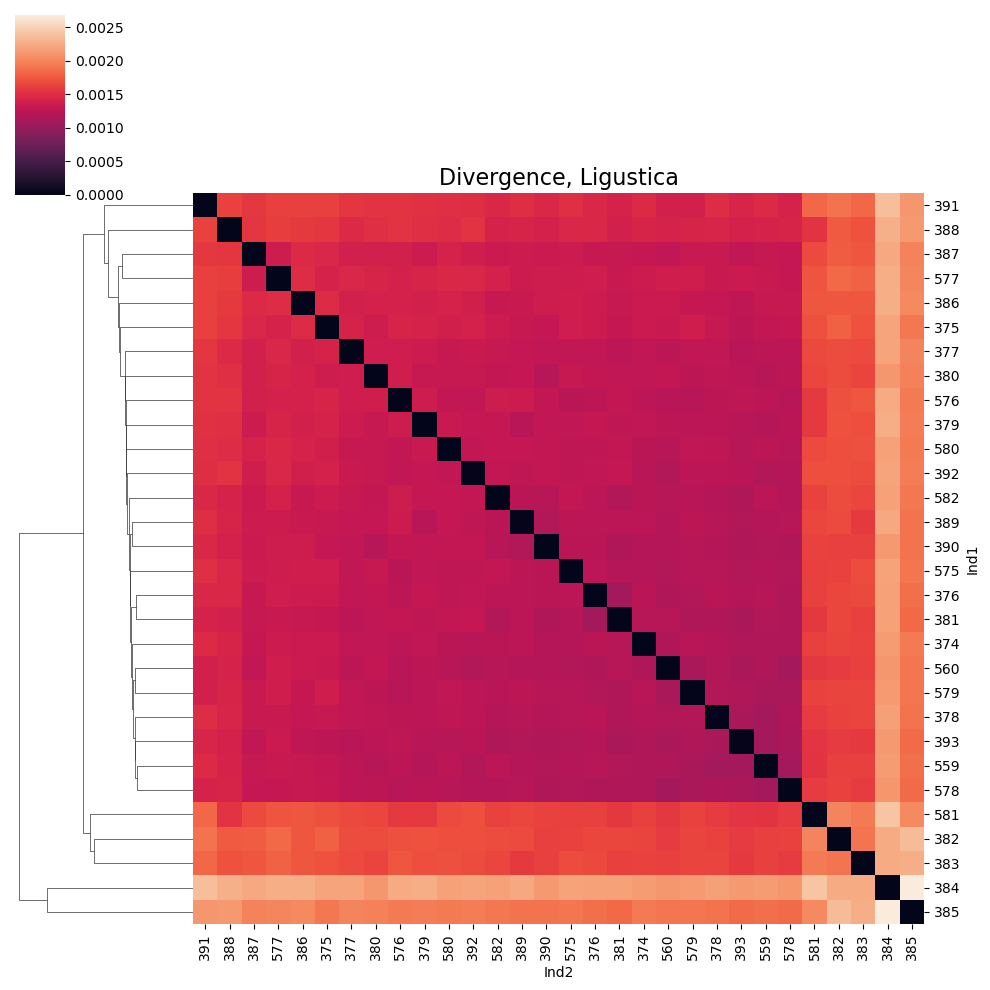

In [68]:
name = "Ligustica"
m = indPairsDivergenceDF_removed[(indPairsDivergenceDF_removed.PopPair == "Same") & (indPairsDivergenceDF.Subpop1 == name)][["Ind1", "Ind2", "Divergence"]]
m1 = m.copy()
m1.columns = ["Ind2", "Ind1", "Divergence"]
matrix = m.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrix1 = m1.pivot(index='Ind1', columns='Ind2', values='Divergence').fillna(0)
matrixAll = matrix + matrix1
import scipy
row_linkage = scipy.cluster.hierarchy.linkage(matrixAll, method="average")
order = scipy.cluster.hierarchy.leaves_list(row_linkage)
x_pop = [int(x) for x in matrixAll.index.values[order]]
clustermap = sns.clustermap(matrixAll[x_pop], row_linkage=row_linkage, col_cluster=False)

# Add title
clustermap.ax_heatmap.set_title("Divergence, " + name, fontsize=16)

plt.show()

In [73]:
indPairsDivergenceDF[indPairsDivergenceDF.Ind1 == 312]

,Divergence,Pair,Ind1,Ind2,Subpop1,Subpop2,PopPair,Family1,Family2,IndName1,IndName2,FamilyPair
134940,NaN,"(312, 312)",312,312,Mellifera,Mellifera,Same,NaN,NaN,SRR15173529,SRR15173529,Different
134941,0.004412,"(312, 313)",312,313,Mellifera,Mellifera,Same,NaN,NaN,SRR15173529,SRR15173530,Different
134942,0.004440,"(312, 314)",312,314,Mellifera,Mellifera,Same,NaN,NaN,SRR15173529,SRR15173531,Different
134943,0.004399,"(312, 315)",312,315,Mellifera,Mellifera,Same,NaN,NaN,SRR15173529,SRR15173532,Different
134944,0.001517,"(312, 316)",312,316,Mellifera,Carnica,Different,NaN,NaN,SRR15173529,SRR15173533,Different
...,...,...,...,...,...,...,...,...,...,...,...,...
135211,0.004354,"(312, 583)",312,583,Mellifera,Mellifera,Same,NaN,NaN,SRR15173529,SRR6236955,Different
135212,0.004179,"(312, 584)",312,584,Mellifera,Mellifera,Same,NaN,NaN,SRR15173529,SRR6236956,Different
135213,0.004427,"(312, 585)",312,585,Mellifera,Mellifera,Same,NaN,NaN,SRR15173529,SRR6236961,Different
135214,0.002253,"(312, 586)",312,586,Mellifera,Caucasia,Different,NaN,NaN,SRR15173529,SRR6236969,Different


In [74]:
sibsMeta[sibsMeta.ENA_Run == "SRR15173529"]

,ENA_Run,ENA_Project,ENA_Sample,Sample_ID,Sample_Locale,Sample_Country,Sample_Continent,Reported_Sibling,Reported_Type,Reported_Lineage,Notes
655,SRR15173529,PRJNA311274,SAMN20257376,SOL9,Sollies,France,Europe,nan,Mellifera,M,Conservatory
